# CellVOCAL example: public human-kidney Slide-seq data

This notebook covers downloading the input, preparing data, configuring and
training a model, and loading results. Downstream analysis uses the functions
in `utils`.

**Training is commented out by default.** Run All loads an existing example
fit. If the result and checkpoint are absent, uncomment the training cell once.

The setup resolves `ROOT` from the current project directory. Input data are
downloaded when absent, and fitted results are stored under `example/cellvocal/`.

## Data source

The public processed dataset is HuBMAP **HBM986.KFWG.239**, linked to
[HBM554.DHLV.735](https://doi.org/10.35079/HBM554.DHLV.735).
The complete original file has **35,052 spatial beads × 60,286 genes** and
contains measured `spliced`/`unspliced` count layers, real `X_spatial`
coordinates, and source-provided `hugo_symbol` annotations.
It is separate from the manuscript datasets and is used under
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

Source: [HuBMAP dataset page](https://portal.hubmapconsortium.org/browse/dataset/21cfe0f6c3368b06237716a6b48f5825).
The [processing documentation](https://docs.hubmapconsortium.org/assays/rnaseq.html)
defines exonic/spliced and intronic/unspliced counts; Salmon counts can be
fractional. Cite the dataset and the
[Slide-seq study](https://doi.org/10.1126/science.aaw1219).
The original ~126 MiB input was retrieved on 2026-10-08 and is retained
unchanged. Download URLs and the SHA-256 are recorded below.

## 1. Environment and original input

Start Jupyter from the repository root or `example/`. Reuse a verified local
file; only download if absent. The original file is never overwritten by input
assembly or model fitting.

In [1]:
import os
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(key, "4")

import base64
import hashlib
import sys
import urllib.request
from pathlib import Path
import anndata as ad
import numpy as np
import pandas as pd
from scipy import sparse
import torch
from IPython.display import HTML, Image, display

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "pipeline" / "cellvocal.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "pipeline" / "cellvocal.py").is_file():
    raise RuntimeError("Start Jupyter from the CellVOCAL repository root or example directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from model.train.config import CellVOCALConfig
from model.train.qc import apply_rna_velocity_qc
from model.graph.lr_prior import prepare_lr_pairs_for_cellvocal
from model.train.checkpoint import load_cellvocal_checkpoint
from pipeline.cellvocal import run_cellvocal
from utils.tools.clustering import pca
from utils.viz.velocity import VelocityEmbeddingPlotter
from utils.viz.lr_spatial import LRSpatialPlotter, parse_lr_pairs

torch.set_num_threads(4)
DATA_DIR = ROOT / "example" / "data"
OUTPUT_DIR = ROOT / "example" / "cellvocal"
FIG_DIR = OUTPUT_DIR / "figures"
INPUT_PATH = DATA_DIR / "human_kidney_slideseq.h5ad"
SOURCE_URL = "https://assets.hubmapconsortium.org/cdf9127efdfc96189845c35244d4d8ab/expr.h5ad"
SOURCE_SIZE = 131875528
SOURCE_SHA256 = "19bfaeb96e900dc76f39d3d6063e8594c07eae05f89b6340572fbd843ad36d8f"
print("Repository: CellVOCAL")
print("Example output:", OUTPUT_DIR.relative_to(ROOT))

In [2]:
DATA_DIR.mkdir(parents=True, exist_ok=True)
if not INPUT_PATH.is_file():
    temporary = INPUT_PATH.with_suffix(".h5ad.part")
    request = urllib.request.Request(SOURCE_URL, headers={"User-Agent": "CellVOCAL-example"})
    try:
        with urllib.request.urlopen(request, timeout=60) as response, temporary.open("wb") as handle:
            for block in iter(lambda: response.read(1024 * 1024), b""):
                handle.write(block)
        digest = hashlib.sha256()
        with temporary.open("rb") as handle:
            for block in iter(lambda: handle.read(1024 * 1024), b""):
                digest.update(block)
        if temporary.stat().st_size != SOURCE_SIZE or digest.hexdigest() != SOURCE_SHA256:
            raise ValueError("Downloaded input does not match the pinned original")
        temporary.replace(INPUT_PATH)
    finally:
        temporary.unlink(missing_ok=True)

digest = hashlib.sha256()
with INPUT_PATH.open("rb") as handle:
    for block in iter(lambda: handle.read(1024 * 1024), b""):
        digest.update(block)
assert INPUT_PATH.stat().st_size == SOURCE_SIZE
assert digest.hexdigest() == SOURCE_SHA256
source = ad.read_h5ad(INPUT_PATH)
assert source.shape == (35052, 60286)
assert source.obs_names.is_unique and source.var_names.is_unique
assert np.asarray(source.obsm["X_spatial"]).shape == (source.n_obs, 2)
print("Verified full original:", source.shape, round(SOURCE_SIZE / 2**20, 2), "MiB")
print("Layers:", list(source.layers))

Verified full original: (35052, 60286) 125.77 MiB
Layers: ['spliced', 'spliced_unspliced_sum', 'unspliced']


## 2. Assemble the model input

Keep all source beads. Use the source gene-symbol annotation; missing symbols
retain Ensembl IDs. Repeated symbols are summed with one shared sparse mapping
for both count layers, preserving each bead's counts. The model's standard QC
will filter the working copy later. This preparation does not change the
original file or invent cell types, histology, coordinates, or RNA counts.

In [3]:
source_ids = source.var_names.astype(str).to_numpy()
annotation = source.var["hugo_symbol"].astype(object)
symbols = annotation.where(annotation.notna(), "").astype(str).str.strip().to_numpy()
missing = np.isin(symbols, ["", "nan", "None", "<NA>"])
symbols[missing] = source_ids[missing]
codes, gene_names = pd.factorize(symbols, sort=False)
gene_map = sparse.csr_matrix(
    (np.ones(source.n_vars), (np.arange(source.n_vars), codes)),
    shape=(source.n_vars, len(gene_names)),
)
source_gene_groups = [[] for _ in gene_names]
for gene_id, group in zip(source_ids, codes, strict=True):
    source_gene_groups[group].append(gene_id)

layers = {}
for key in ("spliced", "unspliced"):
    counts = sparse.csr_matrix(source.layers[key], dtype=np.float64)
    assert counts.shape == source.shape
    assert np.isfinite(counts.data).all() and np.all(counts.data >= 0)
    combined = (counts @ gene_map).tocsr()
    np.testing.assert_allclose(np.asarray(combined.sum(1)), np.asarray(counts.sum(1)), rtol=1e-12, atol=1e-10)
    layers[key] = combined

xy = np.asarray(source.obsm["X_spatial"])
assert np.isfinite(xy).all()
adata = ad.AnnData(
    X=layers["spliced"] + layers["unspliced"],
    obs=source.obs.copy(),
    var=pd.DataFrame({"source_gene_ids": [";".join(ids) for ids in source_gene_groups]}, index=pd.Index(gene_names, name="gene_symbol")),
    layers=layers,
    obsm={"spatial": xy.copy(), "X_spatial": xy.copy()},
)
assert adata.obs_names.equals(source.obs_names)
print("Assembled full input:", adata.shape)
print("Missing symbols retained as Ensembl IDs:", int(missing.sum()))
print("Duplicate feature columns merged:", source.n_vars - adata.n_vars)
del source, layers, counts, combined, gene_map

Assembled full input: (35052, 59306)
Missing symbols retained as Ensembl IDs: 3336
Duplicate feature columns merged: 980


## 3. Configuration and input coverage

Use `CellVOCALConfig` defaults, adjusting only the human database, example
output paths and CPU fallback. The default weak time prior uses the spatial
x coordinate; normalized model time is not experimental or clinical time.

The fixed teaching prior below is declared before fitting. Standard QC retains
35,014 beads and 1,740 genes; APP–CD74, COL4A1–SDC4 and COL4A2–SDC4 have
gene/expression support.

In [4]:
config = CellVOCALConfig()
config.translator.cellchat_species = "human"
config.translator.cellchatdb_dir = ROOT / "resource" / "cellchatdb"
config.train.checkpoint_dir = OUTPUT_DIR / "checkpoints"
config.eval.output_dir = OUTPUT_DIR / "results"
if not torch.cuda.is_available():
    config.train.device = "cpu"

fixed_interactions = [
    "APP_CD74", "APP_SORL1", "APP_TNFRSF21", "CD99_CD99", "CD99_CD99L2",
    "FN1_SDC1", "FN1_SDC4", "FN1_CD44", "COL4A1_CD44", "COL4A2_CD44",
    "COL4A1_SDC1", "COL4A2_SDC1", "COL4A1_SDC4", "COL4A2_SDC4",
    "LAMB1_DAG1", "LAMB2_DAG1", "LGALS9_P4HB", "LGALS9_CD44", "MDK_NCL", "MDK_LRP1",
]
database = pd.read_csv(config.translator.cellchatdb_dir / "CellChatDB.human.csv").fillna("").set_index("interaction_name")
prior = []
for name in fixed_interactions:
    row = database.loc[name]
    assert not row["co_A_receptor"] and not row["co_I_receptor"]
    prior.append({"interaction": name, "pathway": row["pathway_name"], "ligand": row["ligand.symbol"], "receptor": row["receptor.symbol"]})
preview = apply_rna_velocity_qc(adata, copy=True, **vars(config.qc))
lr_pairs = prepare_lr_pairs_for_cellvocal(preview, config, lr_pairs=prior)
assert len(lr_pairs) >= 2
print("QC input:", preview.shape)
print("Training device when enabled:", config.train.device)
display(pd.DataFrame(lr_pairs)[["interaction", "ligand", "receptor"]])
del preview

RNA velocity QC: 35014/35052 spots, 1740/59306 genes retained


QC input: (35014, 1740)
Training device when enabled: cuda:0


,interaction,ligand,receptor
0,APP_CD74,APP,CD74
1,COL4A1_SDC4,COL4A1,SDC4
2,COL4A2_SDC4,COL4A2,SDC4


## 4. Optional training

Uncomment only for the first fit or an explicit refit of this example.
The public pipeline applies QC once to the assembled input and saves only
under `example/cellvocal/`. Run All otherwise uses the existing saved model.

In [5]:
# result = run_cellvocal(
#     adata,
#     config=config,
#     lr_pairs=lr_pairs,
# )

## 5. Load saved output

The displayed fit uses translator mode `off` and an RNA-maturity weak time
prior, with 3 LR modules and 36,482 events. New fits use the configuration
above, so their results can differ from the displayed fit.

Load the saved model strictly on CPU, using its checkpoint configuration
(`fitted_config`). This cell does not fit or update any weights.

In [6]:
result_path = OUTPUT_DIR / "results" / "out.h5ad"
checkpoint_path = OUTPUT_DIR / "checkpoints" / "cellvocal.pt"
if not result_path.is_file() or not checkpoint_path.is_file():
    raise FileNotFoundError("Uncomment the training cell once to create the example result")
result = ad.read_h5ad(result_path)
model, fitted_config, model_meta = load_cellvocal_checkpoint(checkpoint_path, map_location="cpu")
model.eval()
assert result.n_vars == model_meta["n_genes"]
assert len(result.uns["cv_ccc"]["lr_pairs"]) == model_meta["n_modules"]
print(result)
print("Saved model epoch:", model_meta["epoch"])
print("Saved translator mode:", fitted_config.translator.mode)
print("Saved time prior:", fitted_config.train.time_prior_source)
print("Modules:", list(result.uns["cv_ccc"]["lr_pairs"]))
print("Events:", len(result.uns["cv_ccc"]["sender"]))
display(result.obs[["cv_time"]].head())

AnnData object with n_obs × n_vars = 35014 × 1740
    obs: 'cellvocal_qc_total_spliced_counts', 'cellvocal_qc_total_unspliced_counts', 'cellvocal_qc_total_velocity_counts', 'cellvocal_qc_n_velocity_genes_by_counts', 'cv_time'
    var: 'source_gene_ids', 'n_source_gene_ids', 'hugo_symbol', 'used_ensembl_fallback', 'cellvocal_qc_spliced_counts', 'cellvocal_qc_unspliced_counts', 'cellvocal_qc_shared_counts', 'cellvocal_qc_spliced_cells', 'cellvocal_qc_unspliced_cells', 'cellvocal_qc_shared_cells'
    uns: 'cellvocal_qc', 'cv_ccc', 'dataset_provenance', 'example_preprocessing'
    obsm: 'X_spatial', 'cv_latent', 'spatial'
    layers: 'cv_ccc_velocity', 'cv_intrinsic_velocity', 'cv_velocity', 'spliced', 'unspliced'
    obsp: 'spatial_connectivities'
Saved model epoch: 52
Saved translator mode: off
Saved time prior: rna_maturity
Modules: ['APP->CD74', 'COL4A1->SDC4', 'COL4A2->SDC4']
Events: 36482


,cv_time
AAAAAAACTGCTGT,0.496361
AAAAAACACTTTTT,0.469791
AAAAACCCAGCCGA,0.475675
AAAAACCGCCTTAG,0.501522
AAAAACCTTAGGCT,0.525381


## 6. whole-slice normalized model time

Use `VelocityEmbeddingPlotter.plot_latent_time` on all post-QC beads.
This is the learned RNA-state ordering, not measured disease progression.

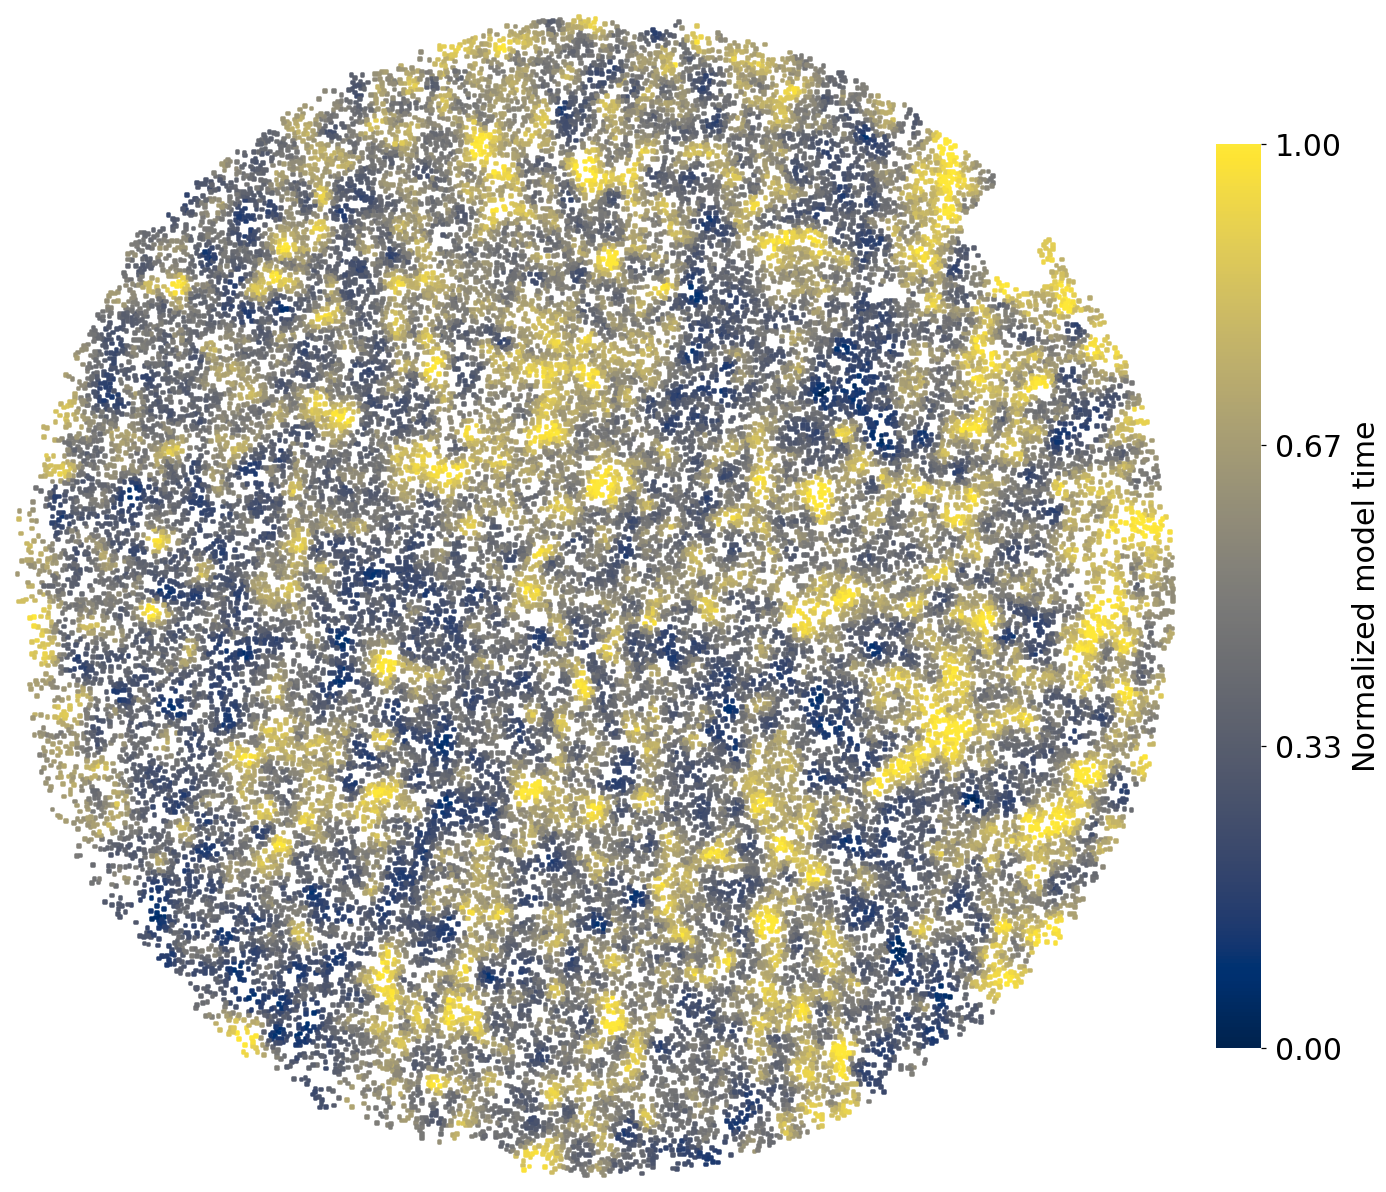

In [7]:
time_plotter = VelocityEmbeddingPlotter(
    FIG_DIR / "latent_time", tag="cv", cluster_key="cv_time", n_jobs=1, dpi=180,
    latent_time_kwargs={"cbar_label": "Normalized model time"},
)
time_figure = time_plotter.plot_latent_time(result)
display(Image(filename=str(time_figure), width=650))

## 7. Prepare one local view of the saved fit

For a compact communication view, take 150 active receiver beads nearest the
slice's median coordinate and include **all** their fitted senders. This only
selects a display region; the model was fitted to the full QC-filtered slice.
Event indices are remapped to the view, while the original event influences,
module gates and sender shares are unchanged. The local event table retains
all sender competitors for every selected receiver-module group.

In [8]:
ccc = dict(result.uns["cv_ccc"])
receiver = np.asarray(ccc["receiver"], dtype=np.int64)
sender = np.asarray(ccc["sender"], dtype=np.int64)
xy = np.asarray(result.obsm["spatial"])
eligible = np.unique(receiver)
distance = np.sum((xy[eligible] - np.median(xy, axis=0)) ** 2, axis=1)
focal = eligible[np.argsort(distance, kind="stable")[:150]]
keep_events = np.isin(receiver, focal)
bead_ids = np.unique(np.r_[focal, sender[keep_events]])
case = result[bead_ids].copy()
index_map = np.full(result.n_obs, -1, dtype=np.int64)
index_map[bead_ids] = np.arange(len(bead_ids))
local_ccc = {}
for key, value in ccc.items():
    array = np.asarray(value)
    local_ccc[key] = array[keep_events] if array.ndim > 0 and array.shape[0] == len(receiver) else value
local_ccc["sender"] = index_map[sender[keep_events]]
local_ccc["receiver"] = index_map[receiver[keep_events]]
case.uns["cv_ccc"] = local_ccc
print("Display only:", case.n_obs, "beads;", int(keep_events.sum()), "original fitted events")

Display only: 205 beads; 409 original fitted events


## 8. RNA velocity in local transcriptional PCA space

Use `utils.tools.clustering.pca` and
`VelocityEmbeddingPlotter.plot_velocity_streams`. The chosen coordinates are
RNA PCA, not tissue x/y. Internally the plotter uses its generic 2D coordinate
interface and scVelo's embedding projection. The original tissue coordinates and the saved model are untouched.
The color is normalized model time. No physical migration is inferred.

or is corrupted (e.g. due to subsetting). Consider recomputing with `pp.neighbors`.
computing neighbors


    finished (0:00:14) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing velocity graph (using 1/64 cores)


  0%|          | 0/205 [00:00<?, ?cells/s]

    finished (0:00:00) --> added 
    'cv_velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'cv_velocity_spatial', embedded velocity vectors (adata.obsm)


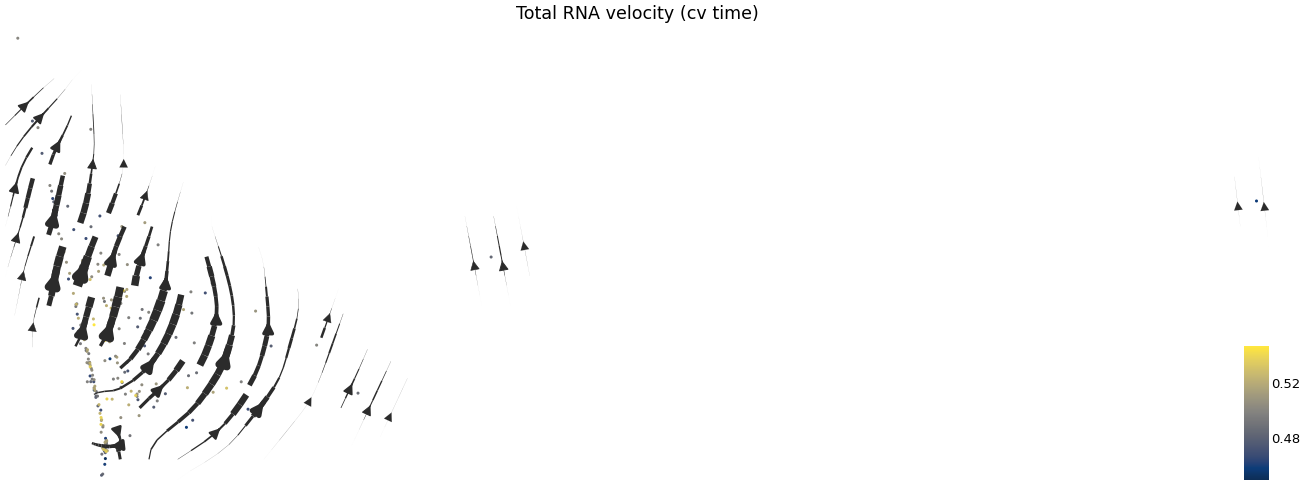

In [9]:
rna = ad.AnnData(
    X=case.layers["spliced"].copy(),
    obs=case.obs[["cv_time"]].copy(),
    var=case.var.copy(),
    layers={"spliced": case.layers["spliced"].copy(), "unspliced": case.layers["unspliced"].copy(), "cv_velocity": case.layers["cv_velocity"].copy()},
)
rna.obsm["X_pca"] = pca(rna, n_comps=2)
velocity_plotter = VelocityEmbeddingPlotter(
    FIG_DIR / "rna_pca", tag="cv", spatial_key="X_pca", cluster_key="cv_time",
    velocity_color_keys=["cv_time"], n_jobs=1, dpi=180,
)
velocity_figures = velocity_plotter.plot_velocity_streams(rna)
for path in velocity_figures:
    display(Image(filename=str(path), width=650))
del rna

## 9. ligand–receptor spatial communication

Call `LRSpatialPlotter` directly on the local view and display the module maps
in one row. The existing tool uses a dense edge tensor, so a local view avoids
a whole-slice N² allocation. Points are measured beads; arrows are
sender→receiver communication event influences, not RNA-state vectors or cell
motion. Voronoi polygons are plotting boundaries around beads rather than
measured cell outlines.

In [10]:
lr_plotter = LRSpatialPlotter(FIG_DIR / "lr_spatial", prefix="cv")
lr_figures = lr_plotter.plot(
    case,
    ligand_receptor_pairs=parse_lr_pairs(list(local_ccc["lr_pairs"])),
    top_fraction=0.2,
    max_outgoing_edges_per_node=2,
    max_incoming_edges_per_node=2,
    figsize=(5, 5),
)
display(HTML(
    '<div style="display:flex;gap:12px;width:100%;align-items:flex-start;">'
    + "".join(
        '<div style="flex:1;min-width:0;">'
        '<img style="display:block;width:100%;height:auto;" '
        'alt="Ligand–receptor spatial map" src="data:image/svg+xml;base64,'
        + base64.b64encode(Path(path).read_bytes()).decode("ascii")
        + '">'
        + '<div style="text-align:center;font-size:14px;margin-top:4px;">'
        + Path(path).stem.removeprefix("lr_spatial_").replace("_", " → ")
        + '</div></div>'
        for path in lr_figures
    )
    + '</div>'
))